In [16]:
import matplotlib.pyplot as plt
import numpy as np
import pandas

In [17]:
meta = pandas.read_csv("../challenge_data/vm_metadata.csv.gz")

print("--- 1. VM CATEGORY DISTRIBUTION ---")
print(meta["vm_category"].value_counts(dropna=False, normalize=True) * 100)

--- 1. VM CATEGORY DISTRIBUTION ---
vm_category
Delay-insensitive    61.80
Interactive          30.91
Unknown               7.29
Name: proportion, dtype: float64


In [18]:
print("\n--- 2. CORE & MEMORY BUCKETS ---")
print("Top Virtual Core Buckets (%):")
print(
    meta["virtual_core_bucket"].value_counts(dropna=False, normalize=True) * 100
)


--- 2. CORE & MEMORY BUCKETS ---
Top Virtual Core Buckets (%):
virtual_core_bucket
2      75.34
4      19.08
8       4.86
24      0.62
>24     0.10
Name: proportion, dtype: float64


In [19]:
print("\n--- 3. CPU UTILIZATION SKEW ---")
# Check how many VMs are almost completely idle vs maxed out
print(f"Median VM avg_cpu: {meta['avg_cpu'].median():.2f}%")
print(
    f"VMs with avg_cpu < 10%:   {(meta['avg_cpu'] < 10).mean() * 100:.1f}% of VMs"
)
print(
    f"VMs with avg_cpu < 5%:   {(meta['avg_cpu'] < 5).mean() * 100:.1f}% of VMs"
)
print(
    f"VMs with avg_cpu < 1%:   {(meta['avg_cpu'] < 1).mean() * 100:.1f}% of VMs"
)
print(
    f"VMs with p95_max_cpu > 80%: {(meta['p95_max_cpu'] > 80).mean() * 100:.1f}% of VMs"
)


--- 3. CPU UTILIZATION SKEW ---
Median VM avg_cpu: 5.86%
VMs with avg_cpu < 10%:   72.5% of VMs
VMs with avg_cpu < 5%:   43.6% of VMs
VMs with avg_cpu < 1%:   5.3% of VMs
VMs with p95_max_cpu > 80%: 10.2% of VMs


In [20]:
csv_raw = pandas.read_csv("../challenge_data/vm_cpu_readings.csv.gz", header=0)

csv_ts = (
    csv_raw.groupby("timestamp")
    .agg(
        active_vm_count=("vm_id", "nunique"),
        aggregate_cpu_utilization=("avg_cpu", "mean"),
    )
    .reset_index()
    .sort_values("timestamp")
)

train_data = csv_ts[:110]
test_data = csv_ts[110:]
actual_test_cpu = test_data["aggregate_cpu_utilization"].values

print(train_data.shape) # 110 rows, first 9 hours
print(test_data.shape) # 24 rows, last 2 hours

(110, 3)
(24, 3)


In [21]:
print("\n--- 4. VM LIFETIMES & CHURN ---")
# Check if VMs were created before the trace and deleted after
min_trace_time = train_data["timestamp"].min()
max_trace_time = test_data["timestamp"].max()

created_before = (meta["timestamp_vm_created"] <= min_trace_time).mean() * 100
deleted_after = (meta["timestamp_vm_deleted"] >= max_trace_time).mean() * 100

print(f"Trace time window: {min_trace_time} to {max_trace_time}")
print(f"VMs created before trace started: {created_before:.1f}%")
print(f"VMs deleted after trace ended:    {deleted_after:.1f}%")


--- 4. VM LIFETIMES & CHURN ---
Trace time window: 0 to 39900
VMs created before trace started: 100.0%
VMs deleted after trace ended:    100.0%


In [22]:
ml_cpu_forecast = [9.181416917348098, 9.214106533633874, 9.193645238554243, 9.212224816885637, 9.216626220982366, 9.226585926393945, 9.2245864956766, 9.233872030841813, 9.23622520905091, 9.241888915974867, 9.243470513549779, 9.248554474394531, 9.250783020403064, 9.254526364741434, 9.256571281303152, 9.259764945633709, 9.261771775144515, 9.264352266741081, 9.26618372930308, 9.26837483932674, 9.270042661053152, 9.27188601529873, 9.27337732800462, 9.274954562824364]

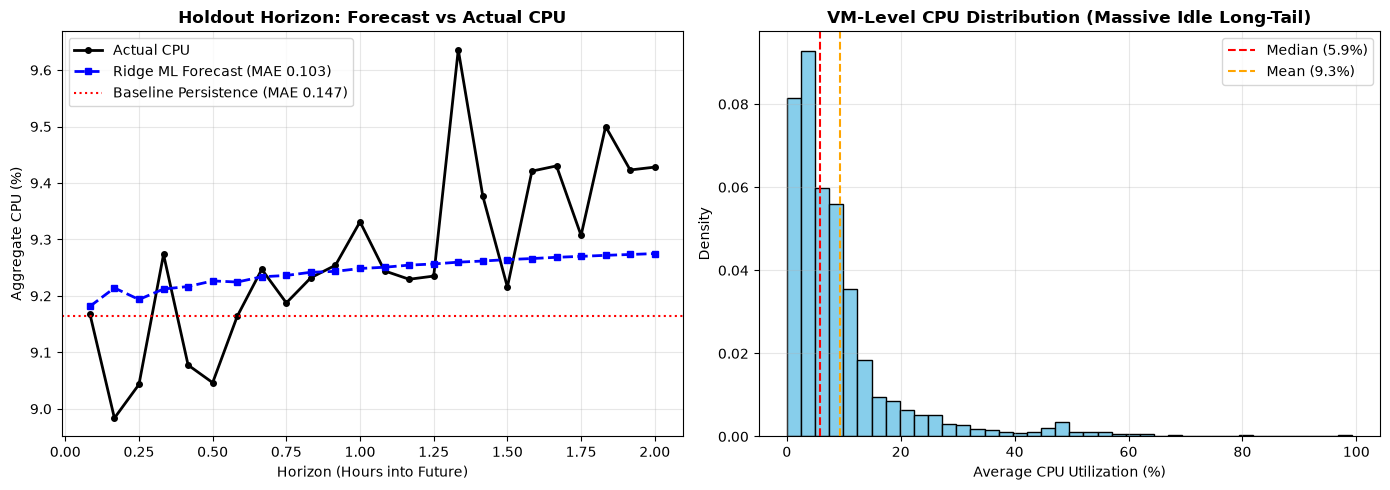


 Saved diagnostic plot as 'eda_and_forecast_results.png'


In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot A: Forecast vs Actual on the 2-hour holdout
time_axis_hrs = np.arange(1, 25) * 5 / 60  # in hours
axes[0].plot(
    time_axis_hrs,
    actual_test_cpu,
    "k-o",
    label="Actual CPU",
    linewidth=2,
    markersize=4,
)
axes[0].plot(
    time_axis_hrs,
    ml_cpu_forecast,
    "b--s",
    label="Ridge ML Forecast (MAE 0.103)",
    linewidth=2,
    markersize=4,
)
axes[0].axhline(
    train_data["aggregate_cpu_utilization"].iloc[-1],
    color="r",
    linestyle=":",
    label="Baseline Persistence (MAE 0.147)",
)
axes[0].set_title(
    "Holdout Horizon: Forecast vs Actual CPU", fontsize=12, fontweight="bold"
)
axes[0].set_xlabel("Horizon (Hours into Future)")
axes[0].set_ylabel("Aggregate CPU (%)")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Plot B: Individual VM CPU Distribution (Log scale or histogram)
axes[1].hist(
    meta["avg_cpu"].dropna(),
    bins=40,
    color="skyblue",
    edgecolor="black",
    density=True,
)
axes[1].axvline(
    meta["avg_cpu"].median(),
    color="red",
    linestyle="--",
    label=f"Median ({meta['avg_cpu'].median():.1f}%)",
)
axes[1].axvline(
    meta["avg_cpu"].mean(),
    color="orange",
    linestyle="--",
    label=f"Mean ({meta['avg_cpu'].mean():.1f}%)",
)
axes[1].set_title(
    "VM-Level CPU Distribution (Massive Idle Long-Tail)",
    fontsize=12,
    fontweight="bold",
)
axes[1].set_xlabel("Average CPU Utilization (%)")
axes[1].set_ylabel("Density")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("test_media/eda_and_forecast_results.png", dpi=300)
plt.show()
print("\n Saved diagnostic plot as 'eda_and_forecast_results.png'")